<a href="https://colab.research.google.com/github/Harshu2202/Wine-quality-prediction/blob/main/wine_quality_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [42]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")


In [43]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [44]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1599
Columns: 12


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [46]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [47]:
print(df.isnull().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [48]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 240


In [49]:
df.drop_duplicates(inplace=True)
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [50]:
print(df['quality'].value_counts().sort_index())

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


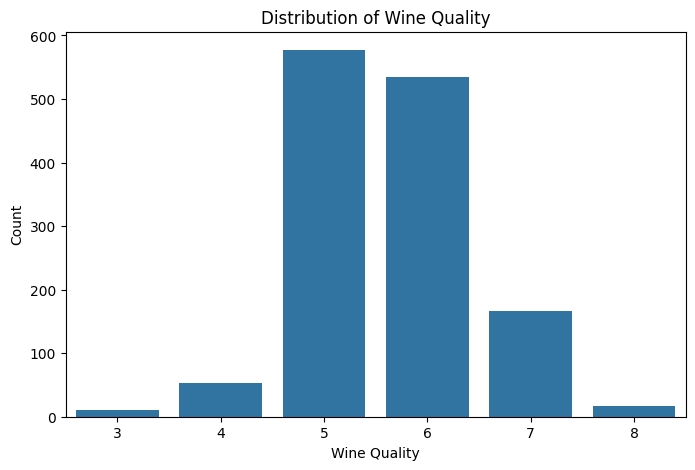

In [51]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='quality')

plt.title('Distribution of Wine Quality')
plt.xlabel('Wine Quality')
plt.ylabel('Count')

plt.show()

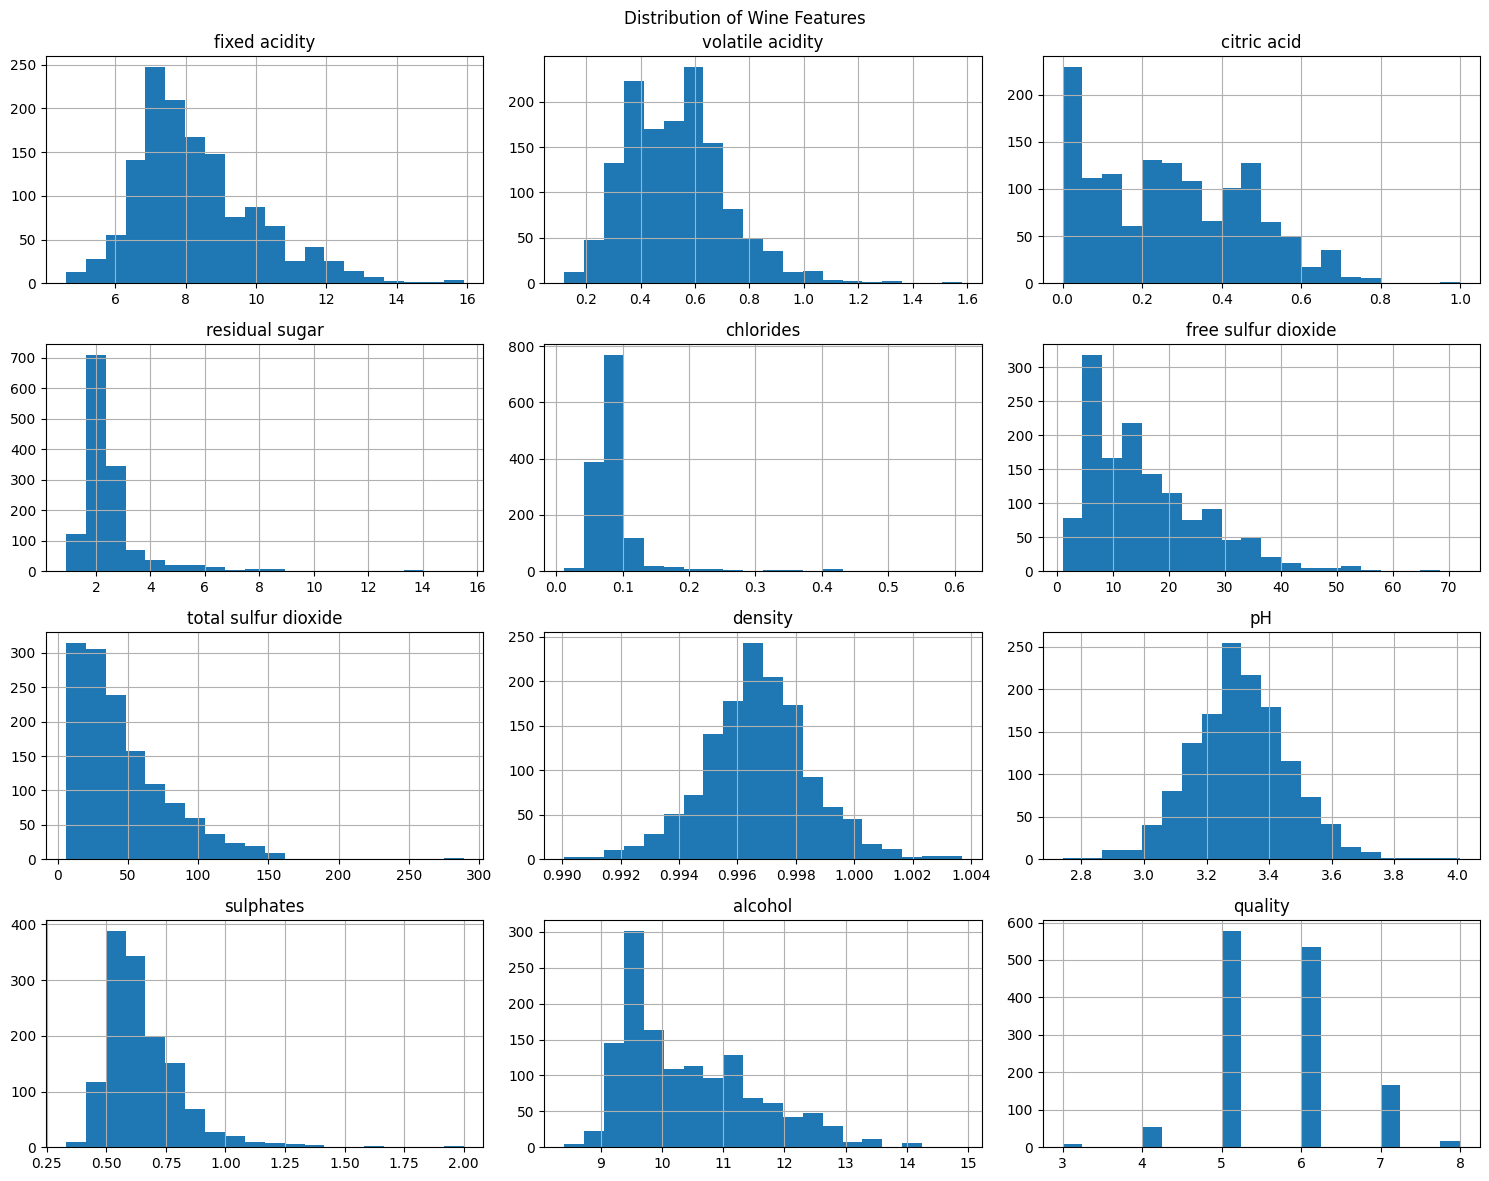

In [52]:
df.hist(figsize=(15,12), bins=20)

plt.suptitle("Distribution of Wine Features")

plt.tight_layout()
plt.show()

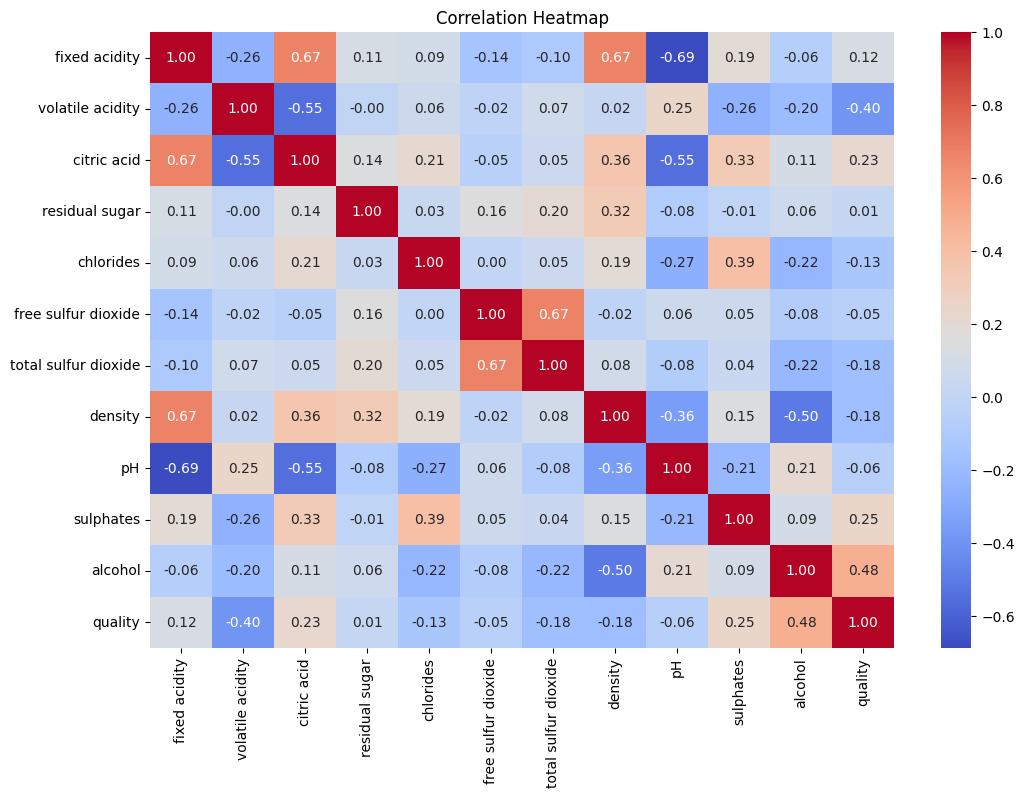

In [53]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

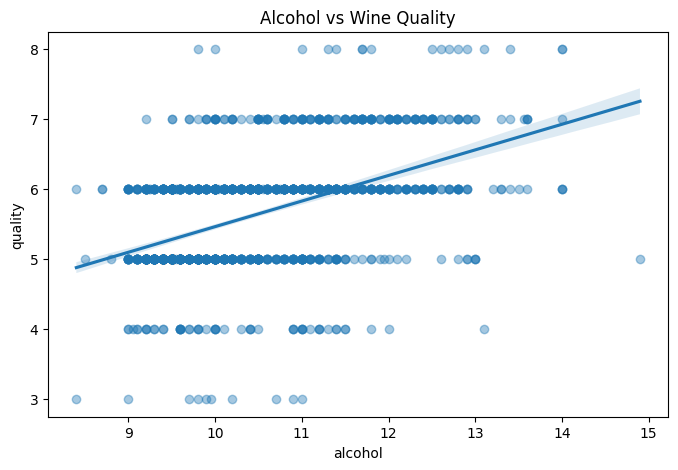

In [54]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df,
    x='alcohol',
    y='quality',
    scatter_kws={'alpha':0.4}
)

plt.title('Alcohol vs Wine Quality')
plt.show()

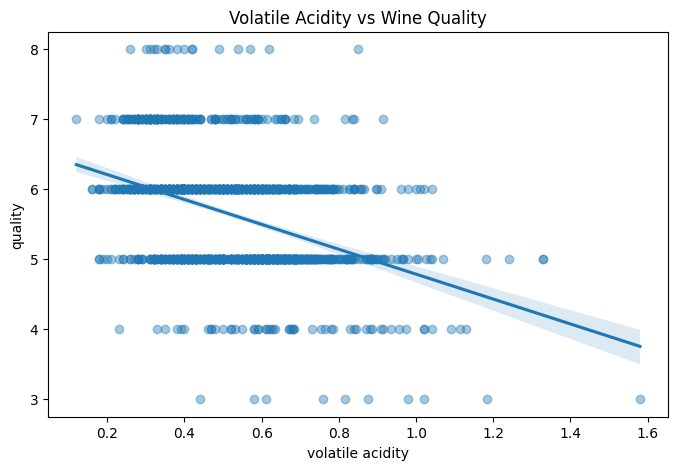

In [55]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df,
    x='volatile acidity',
    y='quality',
    scatter_kws={'alpha':0.4}
)

plt.title('Volatile Acidity vs Wine Quality')
plt.show()

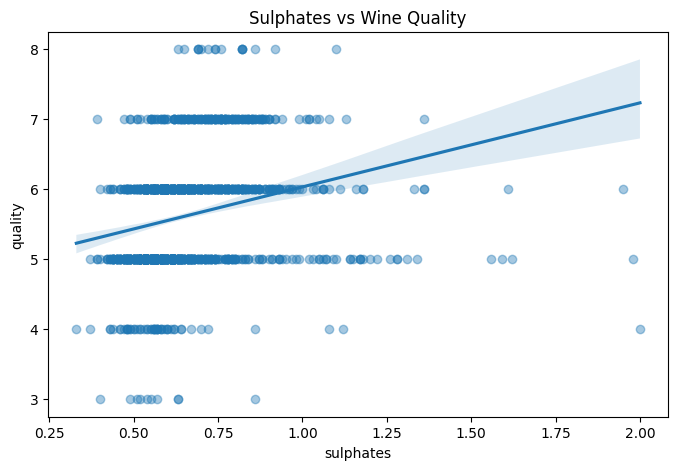

In [56]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=df,
    x='sulphates',
    y='quality',
    scatter_kws={'alpha':0.4}
)

plt.title('Sulphates vs Wine Quality')
plt.show()

In [57]:
X = df.drop('quality', axis=1)

y = df['quality']

print("Independent variables:", X.shape)
print("Dependent variable:", y.shape)

Independent variables: (1359, 11)
Dependent variable: (1359,)


In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1087, 11)
Testing data: (272, 11)


In [59]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

Training data scaled: (1087, 11)
Testing data scaled: (272, 11)


In [60]:
from sklearn.linear_model import LinearRegression

# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [61]:
lr_pred = lr_model.predict(X_test_scaled)

print("First 10 predictions:")
print(lr_pred[:10])

First 10 predictions:
[5.24560141 5.80993501 6.36840525 5.15873325 5.19928608 6.77639051
 5.70671729 4.84475677 5.79995509 5.73940516]


In [62]:
comparison = pd.DataFrame({
    'Actual Quality': y_test.values,
    'Predicted Quality': lr_pred
})

print(comparison.head(10))

   Actual Quality  Predicted Quality
0               5           5.245601
1               6           5.809935
2               7           6.368405
3               5           5.158733
4               4           5.199286
5               7           6.776391
6               5           5.706717
7               5           4.844757
8               6           5.799955
9               5           5.739405


In [63]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Calculate metrics

mae = mean_absolute_error(y_test, lr_pred)

mse = mean_squared_error(y_test, lr_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, lr_pred)

# Display results

print("Linear Regression Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
-------------------------
MAE: 0.5041409053480713
MSE: 0.43100900509009726
RMSE: 0.656512760797608
R2 Score: 0.3915360499058188


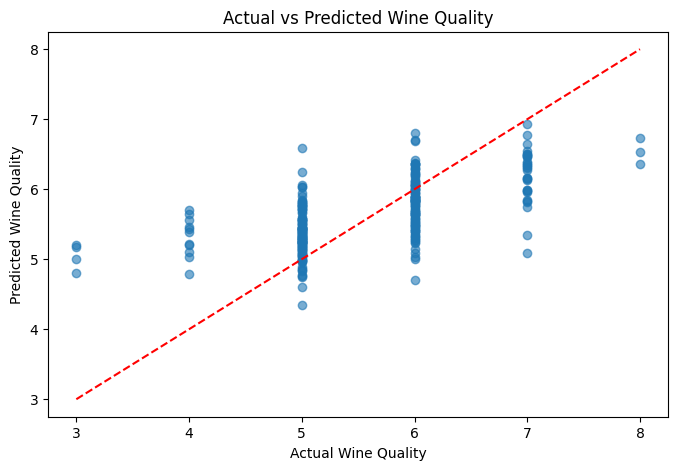

In [64]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, lr_pred, alpha=0.6)

plt.xlabel("Actual Wine Quality")
plt.ylabel("Predicted Wine Quality")

plt.title("Actual vs Predicted Wine Quality")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

In [65]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [66]:
dt_mae = mean_absolute_error(y_test, dt_pred)

dt_mse = mean_squared_error(y_test, dt_pred)

dt_rmse = np.sqrt(dt_mse)

dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Results")
print("---------------------")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Results
---------------------
MAE: 0.49253056857454
MSE: 0.39900766666322934
RMSE: 0.6316705364849855
R2 Score: 0.43671297325906155


In [67]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

In [68]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [69]:

rf_pred = rf_model.predict(X_test)
rf_comparison = pd.DataFrame({
    'Actual Quality': y_test.values,
    'Predicted Quality': rf_pred
})

print(rf_comparison.head(10))

   Actual Quality  Predicted Quality
0               5           5.018744
1               6           5.920391
2               7           6.387162
3               5           5.425544
4               4           5.278632
5               7           6.718221
6               5           5.663776
7               5           5.174747
8               6           5.905766
9               5           5.544930


In [70]:

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)
print("Random Forest Regression Results")
print("--------------------------------")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Regression Results
--------------------------------
MAE: 0.46820839944890147
MSE: 0.3814693972529077
RMSE: 0.6176320889112771
R2 Score: 0.4614720955910637


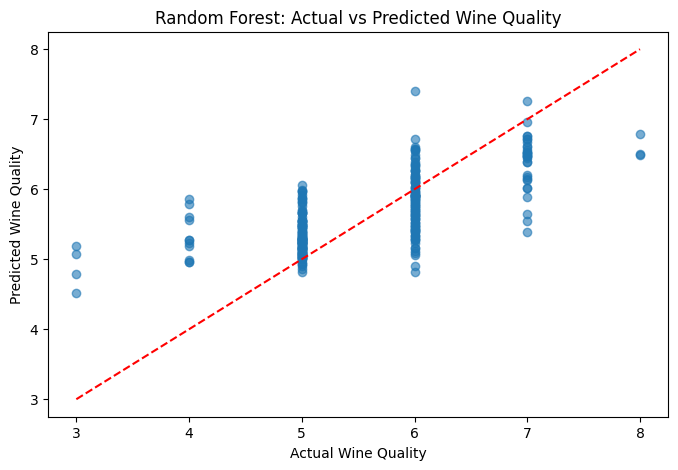

In [71]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, rf_pred, alpha=0.6)

plt.xlabel("Actual Wine Quality")
plt.ylabel("Predicted Wine Quality")

plt.title("Random Forest: Actual vs Predicted Wine Quality")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

In [72]:
results_df = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [mae, dt_mae, rf_mae],
    "MSE": [mse, dt_mse, rf_mse],
    "RMSE": [rmse, dt_rmse, rf_rmse],
    "R2 Score": [r2, dt_r2, rf_r2]
})

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,0.468208,0.381469,0.617632,0.461472
1,Decision Tree,0.492531,0.399008,0.631671,0.436713
0,Linear Regression,0.504141,0.431009,0.656513,0.391536


In [73]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'MAE': [mae, dt_mae, rf_mae],
    'MSE': [mse, dt_mse, rf_mse],
    'RMSE': [rmse, dt_rmse, rf_rmse],
    'R2 Score': [r2, dt_r2, rf_r2]
})

print(model_comparison)

               Model       MAE       MSE      RMSE  R2 Score
0  Linear Regression  0.504141  0.431009  0.656513  0.391536
1      Decision Tree  0.492531  0.399008  0.631671  0.436713
2      Random Forest  0.468208  0.381469  0.617632  0.461472


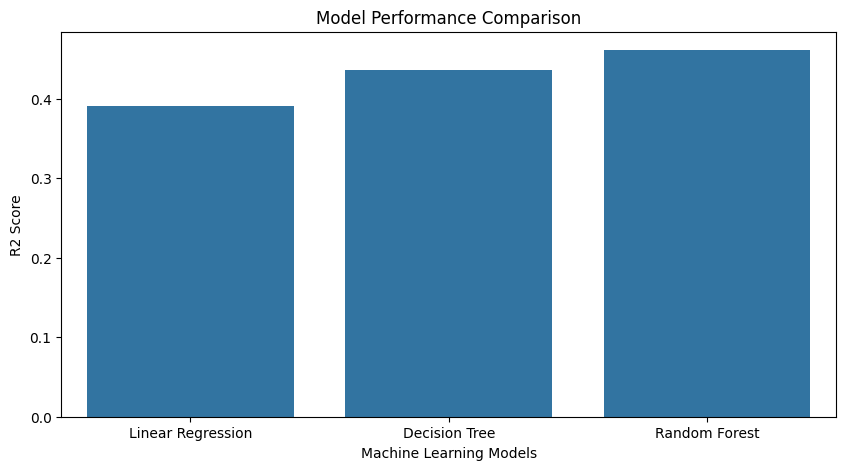

In [74]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='R2 Score'
)

plt.title('Model Performance Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('R2 Score')

plt.show()

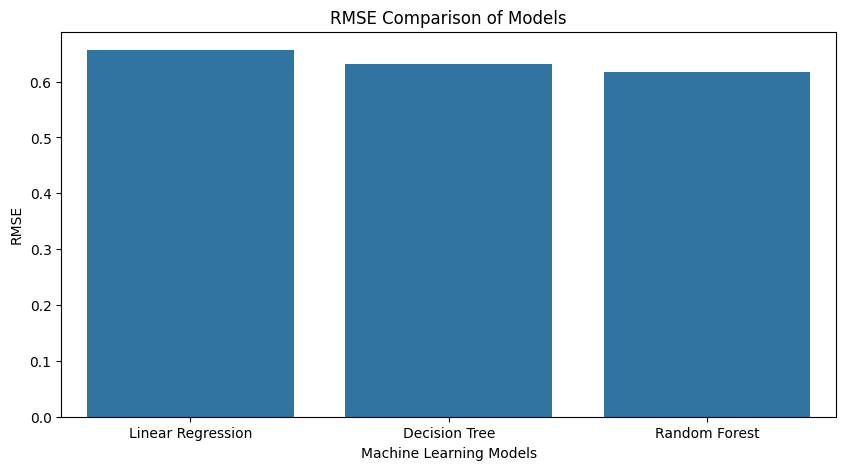

In [75]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='RMSE'
)

plt.title('RMSE Comparison of Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('RMSE')

plt.show()

                 Feature  Importance
10               alcohol    0.305271
9              sulphates    0.140058
1       volatile acidity    0.116776
6   total sulfur dioxide    0.073985
4              chlorides    0.060714
3         residual sugar    0.056693
8                     pH    0.053026
7                density    0.051891
0          fixed acidity    0.050315
5    free sulfur dioxide    0.046933
2            citric acid    0.044339


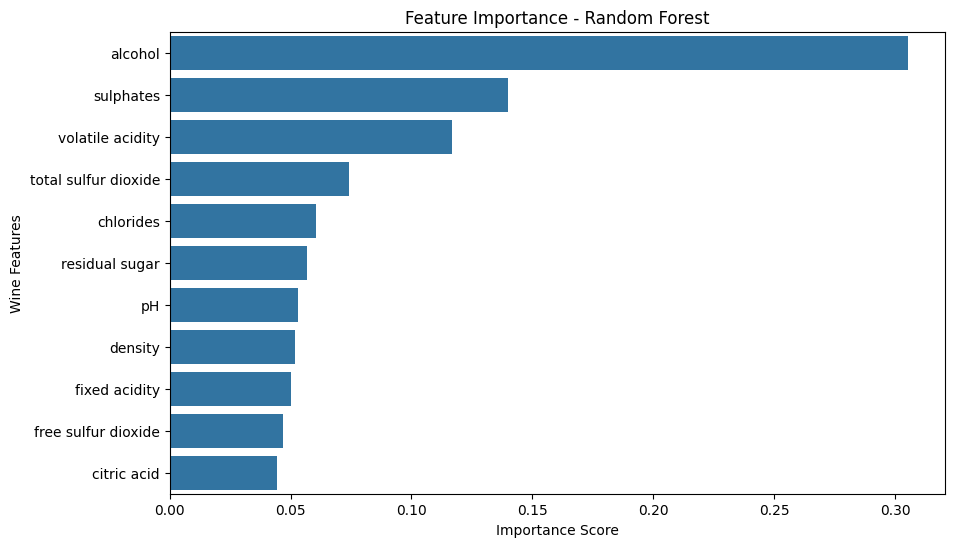

In [76]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Wine Features')

plt.show()

In [77]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring='r2'
)

print("Cross Validation Scores:", cv_scores)

print("Average R2 Score:", cv_scores.mean())

print("Standard Deviation:", cv_scores.std())

Cross Validation Scores: [0.23858709 0.35504636 0.34244265 0.36610981 0.28484727]
Average R2 Score: 0.3174066364008753
Standard Deviation: 0.04834911164005757


In [78]:
new_wine = pd.DataFrame([{
    'fixed acidity': 7.4,
    'volatile acidity': 0.70,
    'citric acid': 0.00,
    'residual sugar': 1.9,
    'chlorides': 0.076,
    'free sulfur dioxide': 11,
    'total sulfur dioxide': 34,
    'density': 0.9978,
    'pH': 3.51,
    'sulphates': 0.56,
    'alcohol': 9.4
}])

predicted_quality = rf_model.predict(new_wine)

print("Predicted Wine Quality:", round(predicted_quality[0], 2))

Predicted Wine Quality: 5.08


In [79]:
import joblib

joblib.dump(rf_model, 'wine_quality_model.pkl')

print("Model saved successfully!")
joblib.dump(list(X.columns), 'wine_features.pkl')

print("Feature list saved successfully!")
loaded_model = joblib.load('wine_quality_model.pkl')

loaded_features = joblib.load('wine_features.pkl')

new_wine = new_wine[loaded_features]

prediction = loaded_model.predict(new_wine)

print("Prediction using saved model:", round(prediction[0], 2))

Model saved successfully!
Feature list saved successfully!
Prediction using saved model: 5.08


In [80]:
from google.colab import files

files.download('wine_quality_model.pkl')
files.download('wine_features.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>